In [11]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
import os
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

zip_path = Path("/content/MRI_Split_Dataset.zip")
extract_path = Path("/content/MRI_Split_Dataset")

if zip_path.exists() and not extract_path.exists():
    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/MRI_Split_Dataset")
    print("Extraction complete!")

# Inspect extracted files to find the correct 'test' folder
base_dir = Path("/content/MRI_Split_Dataset")
test_dir = None

# Search for the directory named 'test' recursively
for root, dirs, files in os.walk(base_dir):
    if "test" in dirs:
        test_dir = Path(root) / "test"
        break

if test_dir is None:
    raise FileNotFoundError("Could not find a 'test' directory inside the extracted zip contents. Please verify the ZIP contents.")

print(f"Found test directory at: {test_dir}")

#Load the models (Already trained)
densenet_model = tf.keras.models.load_model("/content/best_class_weighted.keras")
efficientnet_model = tf.keras.models.load_model("/content/best_efficientnet.keras")

#prepare raw test dataset
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

raw_test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="int",
    class_names=["Normal", "Stroke", "Tumor"],
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

CLASS_NAMES = ["Normal", "Stroke", "Tumor"]

Found test directory at: /content/MRI_Split_Dataset/test
Found 435 files belonging to 3 classes.


In [5]:
#Generate predictions for both models:
print("\nGenerating DenseNet predictions...")
# DenseNet uses preprocess_input from densenet module
from tensorflow.keras.applications.densenet import preprocess_input as densenet_preprocess

def prep_densenet(images, labels):
    return densenet_preprocess(images), labels

test_ds_densenet = raw_test_ds.map(prep_densenet).prefetch(tf.data.AUTOTUNE)
densenet_preds = densenet_model.predict(test_ds_densenet, verbose=1)

print("\nGenerating EfficientNet predictions...")
# EfficientNet in Keras has built-in preprocessing, so we just pass the raw images
def prep_efficientnet(images, labels):
    return images, labels

test_ds_efficientnet = raw_test_ds.map(prep_efficientnet).prefetch(tf.data.AUTOTUNE)
efficientnet_preds = efficientnet_model.predict(test_ds_efficientnet, verbose=1)

y_true = np.concatenate([labels.numpy() for images, labels in raw_test_ds])


Generating DenseNet predictions...
14/14 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step

Generating EfficientNet predictions...
14/14 ━━━━━━━━━━━━━━━━━━━━ 24s 750ms/step


In [6]:
#Find the optimal ensemble weights
best_acc = 0
best_weight = 0

# Test weights from 0.0 to 1.0 (0.05 increments)
for w in np.arange(0, 1.05, 0.05):
    # w = weight for DenseNet, (1-w) = weight for EfficientNet
    blended_preds = (densenet_preds * w) + (efficientnet_preds * (1 - w))
    preds_classes = np.argmax(blended_preds, axis=1)

    acc = accuracy_score(y_true, preds_classes)
    if acc > best_acc:
        best_acc = acc
        best_weight = w
print(f"DenseNet Weight:     {best_weight:.2f}")
print(f"EfficientNet Weight: {1 - best_weight:.2f}")
print(f"Ensemble Test Accuracy: {best_acc * 100:.2f}%")

DenseNet Weight:     0.40
EfficientNet Weight: 0.60
Ensemble Test Accuracy: 97.47%


              precision    recall  f1-score   support

      Normal     0.9504    0.9664    0.9583       119
      Stroke     0.9943    0.9665    0.9802       179
       Tumor     0.9714    0.9927    0.9819       137

    accuracy                         0.9747       435
   macro avg     0.9720    0.9752    0.9735       435
weighted avg     0.9751    0.9747    0.9748       435



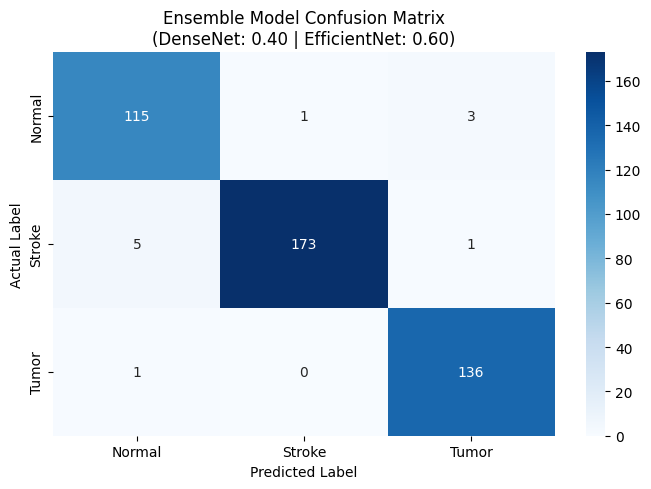

In [7]:
#Final Evaluation and Visualisation - Applying the best weights
final_preds_probs = (densenet_preds * best_weight) + (efficientnet_preds * (1 - best_weight))
final_preds_classes = np.argmax(final_preds_probs, axis=1)

#Classification report
print(classification_report(y_true, final_preds_classes, target_names=CLASS_NAMES, digits=4))

#Confusion Matrix visualisation
cm = confusion_matrix(y_true, final_preds_classes)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Ensemble Model Confusion Matrix\n(DenseNet: {best_weight:.2f} | EfficientNet: {1-best_weight:.2f})")
plt.tight_layout()
plt.show()

In [31]:
#GradCAM implementation
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

#Helper functions:
def get_last_conv_layer_name(model, architecture):
    """Finds the last convolutional layer inside the nested base_model."""
    base_model = None
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model) and architecture.lower() in layer.name.lower():
            base_model = layer
            break

    if base_model is None:
        raise ValueError(f"Could not find {architecture} base model.")

    # Backward iteration - to find Conv2D layer
    for layer in reversed(base_model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
    return None

#Generates the GradCAM heatmap
def make_gradcam_heatmap(img_array, model, inner_model_name, last_conv_layer_name, pred_index=None):
    """Generates the Grad-CAM heatmap supporting nested structures via tape tracing."""
    # 1. Retrieve the inner base model layer
    base_model = model.get_layer(inner_model_name)

    # 2. Get the target conv layer from the base model
    conv_layer = base_model.get_layer(last_conv_layer_name)

    # 3. Build a sub-model for the base model that outputs the target conv layer's activation and the final base output
    # Since these exist in the same functional sub-graph, this will not raise structural mismatch errors
    sub_grad_model = tf.keras.models.Model(
        inputs=base_model.inputs,
        outputs=[conv_layer.output, base_model.output]
    )

    # 4. Use GradientTape to compute gradients relative to the prediction
    with tf.GradientTape() as tape:
        # Forward pass through the sub-model
        conv_outputs, base_preds = sub_grad_model(img_array)

        # Trace the rest of the top-level layers manually
        x = base_preds
        for layer in model.layers:
            if layer.name == inner_model_name:
                continue
            x = layer(x)
        preds = x

        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    # Gradients of the top predicted class with respect to the feature map
    grads = tape.gradient(class_channel, conv_outputs)

    # Global average pooling of the gradients
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Weight the feature map by the gradients
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Apply ReLU and normalize
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-10)
    return heatmap.numpy()

def display_gradcam(img, heatmap, alpha=0.4):
    """Overlays the heatmap on the original image."""
    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    if len(img.shape) == 2:
        img = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

    superimposed_img = heatmap * alpha + img
    superimposed_img = np.clip(superimposed_img, 0, 255).astype(np.uint8)
    return superimposed_img

In [32]:
#Find layer names:
dense_conv_name = get_last_conv_layer_name(densenet_model, "densenet")
eff_conv_name = get_last_conv_layer_name(efficientnet_model, "efficientnet")

print(f"DenseNet last conv layer: {dense_conv_name}")
print(f"EfficientNet last conv layer: {eff_conv_name}")

DenseNet last conv layer: conv5_block16_2_conv
EfficientNet last conv layer: top_conv


In [33]:
#Generate GradCAM visualisation:
for images, labels in raw_test_ds.take(1):
    # Pick the first image in the batch
    raw_img = images[0].numpy()
    true_label = CLASS_NAMES[labels[0].numpy()]

    # Expand dimensions to create a batch of 1
    img_batch = np.expand_dims(raw_img, axis=0)

    # Retrieve base layer names dynamically
    dense_base_name = next(layer.name for layer in densenet_model.layers if isinstance(layer, tf.keras.Model))
    eff_base_name = next(layer.name for layer in efficientnet_model.layers if isinstance(layer, tf.keras.Model))

    #DenseNet Preparation:
    img_densenet = densenet_preprocess(img_batch)
    heatmap_densenet = make_gradcam_heatmap(img_densenet, densenet_model, dense_base_name, dense_conv_name)
    overlay_densenet = display_gradcam(raw_img, heatmap_densenet)

    #EfficientNet Preparation:
    heatmap_efficientnet = make_gradcam_heatmap(img_batch, efficientnet_model, eff_base_name, eff_conv_name)
    overlay_efficientnet = display_gradcam(raw_img, heatmap_efficientnet)

    #Graph:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    #Ensemble model:
    axes[0].imshow(raw_img.astype(np.uint8))
    axes[0].set_title(f"Original MRI\nTrue: {true_label}")
    axes[0].axis('off')

    #DenseNet model:
    axes[1].imshow(overlay_densenet)
    axes[1].set_title("DenseNet121 Grad-CAM")
    axes[1].axis('off')

    #EfficientNet model:
    axes[2].imshow(overlay_efficientnet)
    axes[2].set_title("EfficientNetB0 Grad-CAM")
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


TypeError: too many positional arguments